# Regresja wieloraka – case study: koszt ubezpieczenia

**Plan notatnika:**
1. Regresja wieloraka
2. Dane i eksploracja
3. Przygotowanie danych i pipeline
4. Model podstawowy i ocena
5. Diagnostyka reszt
6. Interpretacja współczynników
7. Ulepszenie modelu: nowa cecha
8. Podsumowanie

## 1. Regresja wieloraka

Dotychczas używaliśmy jednej cechy. **Regresja wieloraka** przewiduje $y$ na podstawie **wielu cech jednocześnie**:

$$y = w_0 + w_1 x_1 + w_2 x_2 + \ldots + w_p x_p + \varepsilon$$

- $w_0$ – wyraz wolny,
- $w_i$ – zmiana przewidywanego $y$, gdy cecha $x_i$ rośnie o 1, **przy pozostałych cechach bez zmian**,
- $\varepsilon$ – część, której model nie wyjaśnia.

Rzeczywistość jest wieloczynnikowa (cena mieszkania zależy od metrażu, lokalizacji, standardu...), więc więcej cech zwykle daje lepsze predykcje. Trzeba jednak uważać na:
- **silnie skorelowane cechy** (utrudniają interpretację współczynników),
- **zbyt wiele cech** względem liczby obserwacji (ryzyko przeuczenia),
- **korelację ≠ przyczynowość**.

**Cel case study:** przewidzieć koszt ubezpieczenia zdrowotnego (`charges`) na podstawie cech klienta.

## 2. Dane i eksploracja

Zbiór `insurance.csv` (1338 klientów): wiek, płeć, BMI, liczba dzieci, palenie, region.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('insurance.csv')
df

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520
...,...,...,...,...,...,...,...
1333,50,male,30.970,3,no,northwest,10600.54830
1334,18,female,31.920,0,no,northeast,2205.98080
1335,18,female,36.850,0,no,southeast,1629.83350
1336,21,female,25.800,0,no,southwest,2007.94500


W zbiorze Insurance.csv (znanym z Kaggle jako Medical Cost Personal Dataset, pochodzącym z książki Bretta Lantza Machine Learning with R) zmienna charges to indywidualne koszty leczenia danej osoby, rozliczone przez ubezpieczenie zdrowotne, wyrażone w dolarach amerykańskich (USD). Zwykle interpretuje się je jako koszty roczne.

In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 73.3 KB


In [3]:
df.describe()

,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


Dane są kompletne (brak braków), 3 kolumny są tekstowe (`sex`, `smoker`, `region`). Przyjrzyjmy się zmiennej docelowej i jej związkom z cechami.

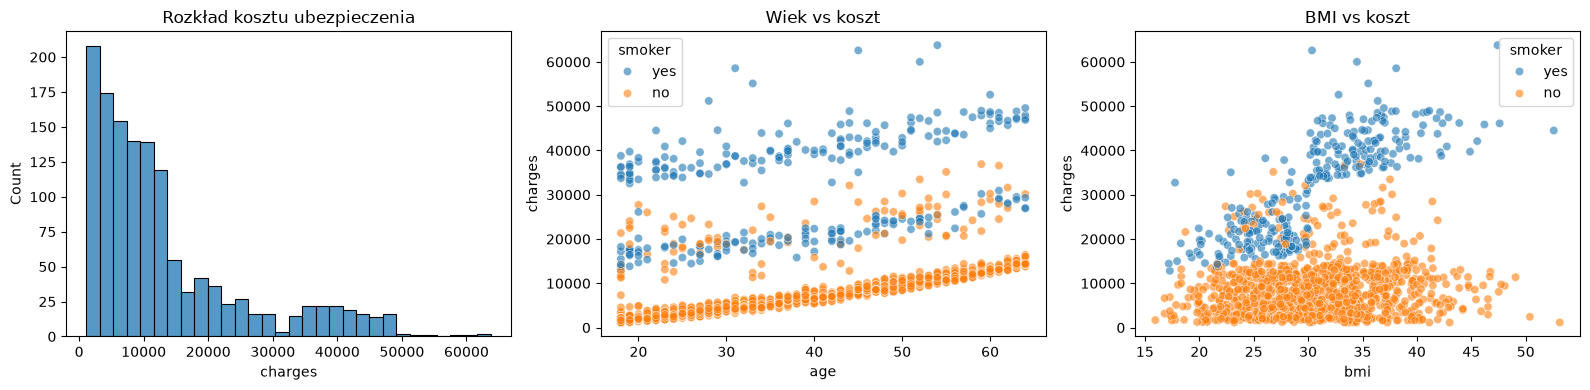

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

sns.histplot(df['charges'], bins=30, ax=axes[0])
axes[0].set_title('Rozkład kosztu ubezpieczenia')

sns.scatterplot(data=df, x='age', y='charges', hue='smoker', alpha=0.6, ax=axes[1])
axes[1].set_title('Wiek vs koszt')

sns.scatterplot(data=df, x='bmi', y='charges', hue='smoker', alpha=0.6, ax=axes[2])
axes[2].set_title('BMI vs koszt')

plt.tight_layout()
plt.show()

**Obserwacje:**
- koszt ma rozkład skośny (kilka bardzo drogich ubezpieczeń),
- koszt rośnie z wiekiem, a punkty tworzą wyraźne „pasma”,
- **palacze** (`smoker = yes`) płacą znacznie więcej,
- wśród palaczy koszt wyraźnie skacze przy BMI około 30.

## 3. Przygotowanie danych i pipeline

1. Oddzielamy zmienną docelową `charges` od cech.
2. Dzielimy dane na zbiór treningowy (80%) i testowy (20%).
3. Kodujemy cechy tekstowe (`OneHotEncoder` z `drop='first'`, notatnik 2.4/01). Cechy liczbowe przekazujemy bez zmian (`passthrough`).
4. Łączymy preprocessing i model w jeden obiekt **`Pipeline`**: `fit()` uczy zarówno encoder, jak i model (tylko na zbiorze treningowym), a `predict()` stosuje oba kroki.

In [4]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score

SEED = 42

X = df.drop(columns='charges')
y = df['charges']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEED)
print(f'X_train: {X_train.shape}, X_test: {X_test.shape}')

X_train: (1070, 6), X_test: (268, 6)


In [6]:
categorical_features = ['sex', 'smoker', 'region']
numeric_features = ['age', 'bmi', 'children']

preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(drop='first', handle_unknown='ignore'), categorical_features),
        ('num', 'passthrough', numeric_features),
    ]
)

model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', LinearRegression()),
])

model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('regressor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](6,)","['age','sex','bmi','children','smoker','region']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,6
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('cat', ...), ('num', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with 

## 4. Model podstawowy i ocena

Porównujemy model z baseline (przewidywanie średniej) na zbiorze testowym.

In [7]:
from sklearn.dummy import DummyRegressor

y_pred = model.predict(X_test)
y_dummy = DummyRegressor().fit(X_train, y_train).predict(X_test)

def metryki(y_true, y_hat):
    return {
        'MAE': mean_absolute_error(y_true, y_hat),
        'RMSE': root_mean_squared_error(y_true, y_hat),
        'R2': r2_score(y_true, y_hat),
    }

wyniki = pd.DataFrame({
    'baseline (średnia)': metryki(y_test, y_dummy),
    'regresja wieloraka': metryki(y_test, y_pred),
}).T
wyniki.round(3)

,MAE,RMSE,R2
baseline (średnia),9593.338,12465.610,-0.001
regresja wieloraka,4181.194,5796.285,0.784


Najprościej przedstawić DummyRegressor jako model, który niczego się nie uczy i służy tylko jako punkt odniesienia (baseline). Ignoruje wszystkie cechy (age, bmi, smoker itd.) i dla każdej osoby przewiduje tę samą liczbę, domyślnie średnią z y w zbiorze treningowym.
Po co taki model? Sam wynik nie mówi zbyt wiele. Jeśli regresja liniowa ma MAE równe 4181 USD, nie wiadomo, czy to dobrze, czy źle. Porównanie z dummy to pokazuje: jeśli „model” przewidujący średnią dla wszystkich ma MAE około 9593 USD, wiemy, że nasz model naprawdę coś wnosi. Jeśli prawdziwy model nie pokonuje dummy, to znaczy, że niczego sensownego się nie nauczył albo coś jest źle w danych lub kodzie.

- Prognoza pogody, która codziennie mówi: „jutro będzie średnia temperatura z tego miesiąca”. Każdy meteorolog musi być lepszy od takiej prognozy, inaczej jest bezużyteczny.
- Uczeń, który na teście jednokrotnego wyboru zawsze zaznacza tę samą odpowiedź. Jego wynik to próg, który trzeba przebić, żeby mówić o jakiejkolwiek wiedzy.


**Jak czytać wyniki:**
- **MAE** – średni błąd predykcji (w jednostkach kosztu),
- **RMSE** – jest większe od MAE, więc są przypadki z dużym błędem,
- **R²** – jaka część zmienności kosztu jest wyjaśniona przez model.

Model jest dużo lepszy od baseline. Sprawdźmy, gdzie się myli najbardziej.

In [9]:
comparison = pd.DataFrame({'y_true': y_test.values, 'y_pred': y_pred})
comparison['error'] = comparison['y_true'] - comparison['y_pred']
comparison['abs_error'] = comparison['error'].abs()

comparison.sort_values('abs_error', ascending=False).head(10).round(0)

,y_true,y_pred,error,abs_error
266,63770.0,40920.0,22850.0,22850.0
203,22494.0,2603.0,19890.0,19890.0
110,23083.0,3281.0,19802.0,19802.0
143,33472.0,14561.0,18911.0,18911.0
116,30260.0,13108.0,17152.0,17152.0
52,28477.0,12365.0,16112.0,16112.0
246,20178.0,4575.0,15603.0,15603.0
67,25993.0,10930.0,15063.0,15063.0
186,20278.0,5919.0,14359.0,14359.0
241,44585.0,31161.0,13424.0,13424.0


## 5. Diagnostyka reszt

Stosujemy wiedzę z notatnika 00: wykres reszt względem przewidywań powinien być losowy, bez wzoru.

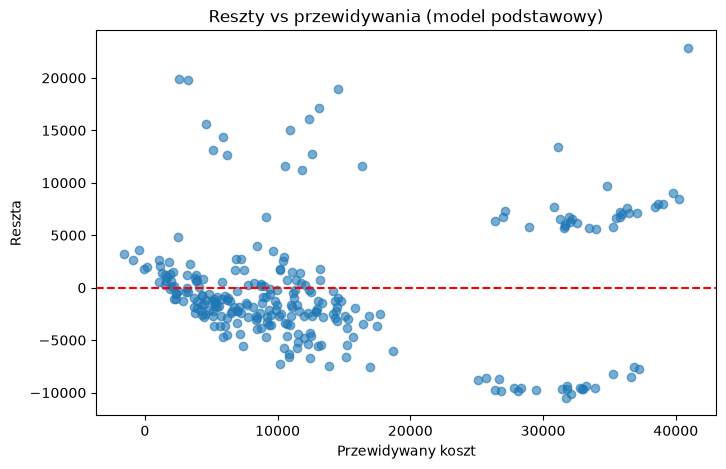

In [10]:
residuals = y_test - y_pred

plt.figure(figsize=(8, 5))
plt.scatter(y_pred, residuals, alpha=0.6)
plt.axhline(0, color='red', linestyle='--')
plt.title('Reszty vs przewidywania (model podstawowy)')
plt.xlabel('Przewidywany koszt')
plt.ylabel('Reszta')
plt.show()

Widać **wyraźne struktury**: grupy punktów i bardzo duże dodatnie reszty (model nie przewidział, że część klientów płaci dużo więcej). To sygnał, że w danych jest wzór, którego model nie uchwycił. Wrócimy do tego w sekcji 7.

## 6. Interpretacja współczynników

Współczynniki mówią, o ile zmienia się przewidywany koszt, gdy dana cecha rośnie o 1 (przy pozostałych bez zmian). Cechy są w **różnych jednostkach** (lata, BMI, 0/1), więc współczynników nie porównujemy wprost jako „ważności” – interpretujemy każdy osobno.

In [11]:
feature_names = model.named_steps['preprocessor'].get_feature_names_out()
coefs = model.named_steps['regressor'].coef_

coef_df = pd.DataFrame({'cecha': feature_names, 'współczynnik': coefs.round(1)})
coef_df

,cecha,współczynnik
0,cat__sex_male,-18.6
1,cat__smoker_yes,23651.1
2,cat__region_northwest,-370.7
3,cat__region_southeast,-657.9
4,cat__region_southwest,-809.8
5,num__age,257.0
6,num__bmi,337.1
7,num__children,425.3


**Przykładowe wnioski** (przy pozostałych cechach bez zmian):
- `smoker_yes` – palacz płaci średnio ok. 23,7 tys. więcej od osoby niepalącej,
- `age` – każdy rok życia podnosi koszt średnio o ok. 257,
- `bmi` – każda jednostka BMI to średnio ok. 337 więcej,
- `children` – każde dziecko to średnio ok. 425 więcej,
- płeć i region mają niewielki wpływ.

Wnioski są spójne z intuicją, ale nie oznaczają związku przyczynowego.

## 7. Ulepszenie modelu: nowa cecha

Z eksploracji wiemy, że wśród palaczy koszt skacze przy BMI ≥ 30 (otyłość). Model liniowy nie potrafi tego sam „zauważyć”, bo wpływ BMI zależy od tego, czy klient pali. Dodajemy cechę-**interakcję**: `smoker_obese` = 1, gdy klient jest palaczem **i** ma BMI ≥ 30 (feature engineering, notatnik 2.4/03).

In [12]:
df2 = df.copy()
df2['smoker_obese'] = ((df2['smoker'] == 'yes') & (df2['bmi'] >= 30)).astype(int)

X2 = df2.drop(columns='charges')
X2_train, X2_test = X2.loc[X_train.index], X2.loc[X_test.index]    # ten sam podział co wcześniej

preprocessor2 = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(drop='first', handle_unknown='ignore'), categorical_features),
        ('num', 'passthrough', numeric_features + ['smoker_obese']),
    ]
)

model2 = Pipeline(steps=[
    ('preprocessor', preprocessor2),
    ('regressor', LinearRegression()),
])
model2.fit(X2_train, y_train)

y_pred2 = model2.predict(X2_test)

In [13]:
wyniki = pd.DataFrame({
    'baseline (średnia)': metryki(y_test, y_dummy),
    'model podstawowy': metryki(y_test, y_pred),
    'model + smoker_obese': metryki(y_test, y_pred2),
}).T
wyniki.round(3)

,MAE,RMSE,R2
baseline (średnia),9593.338,12465.610,-0.001
model podstawowy,4181.194,5796.285,0.784
model + smoker_obese,2486.315,4458.275,0.872


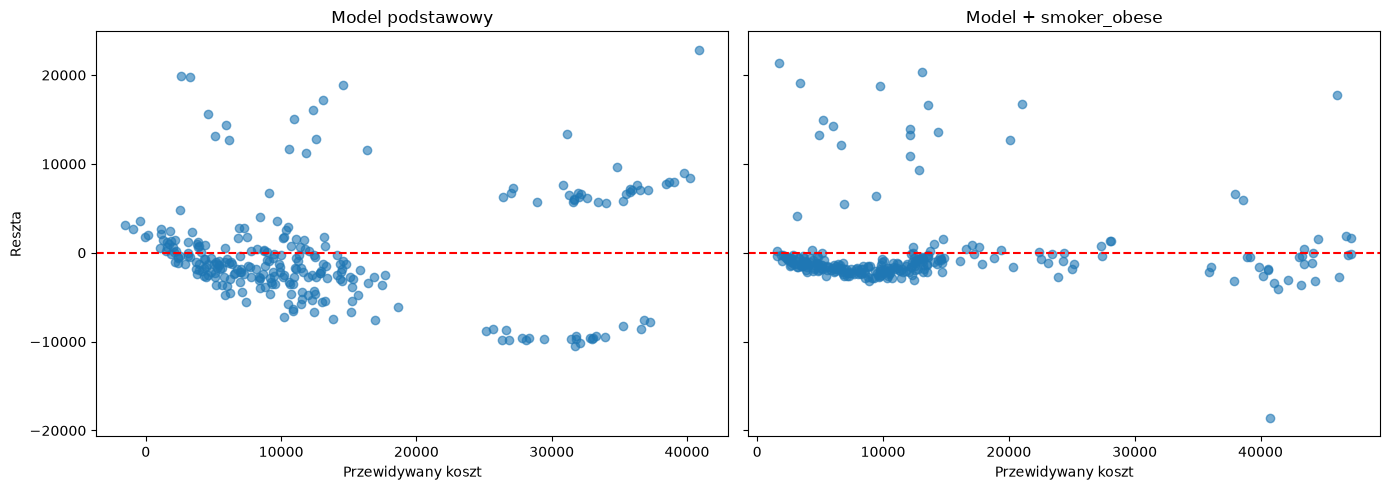

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

for ax, pred, tytul in zip(axes, [y_pred, y_pred2], ['Model podstawowy', 'Model + smoker_obese']):
    ax.scatter(pred, y_test - pred, alpha=0.6)
    ax.axhline(0, color='red', linestyle='--')
    ax.set_title(tytul)
    ax.set_xlabel('Przewidywany koszt')
axes[0].set_ylabel('Reszta')

plt.tight_layout()
plt.show()

Jedna dobrze dobrana cecha zmniejszyła błąd niemal o połowę, a $R^2$ wzrosło z ok. 0,78 do ok. 0,87. Reszty są mniejsze i mniej uporządkowane. **Zrozumienie danych bywa cenniejsze niż bardziej skomplikowany algorytm.**

## 8. Podsumowanie

1. Regresja wieloraka to naturalne rozszerzenie regresji prostej.
2. `Pipeline` łączy preprocessing i model, dzięki czemu unikamy przecieków i błędów przy nowych danych.
3. Zawsze porównuj model z baseline i raportuj kilka metryk (MAE, RMSE, R²).
4. Wykres reszt pokazuje, czego model nie wyjaśnia, i podpowiada, jakie cechy dodać.
5. Współczynniki interpretujemy ostrożnie: przy pozostałych cechach bez zmian i bez wniosków przyczynowych.
6. Kolejny krok: walidacja krzyżowa (rozdział 4.4) i porównanie z innymi modelami.